In [1]:
import sys
from pathlib import Path

# Cherche le dossier racine du projet (BDS_Fault_Detection) pour faire les imports depuis Sources/
dossier = Path().resolve()
for parent in (dossier, *dossier.parents):
    if "BDS_Fault_Detection" in parent.name:
        RACINE = parent
sys.path.insert(0, str(RACINE))

# Importation des fonctions du projet (dossier Sources/). Attention de l'ordre d'importation  !
from Sources import data, config, features, models

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, confusion_matrix
from keras.callbacks import EarlyStopping

I0000 00:00:1795442297.020074    8696 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
DUREE_FENETRE = config.DUREE_FENETRE

def construire_fenetres_brutes(selection, canal="DE", duree=DUREE_FENETRE/2, recouvrement=0.5):
    SB, lignes = [], []
    for nom, info in selection.iterrows():
        s = data.charger(nom, canaux=(canal,))
        for i, val in enumerate(features.fenetrer(s[canal], s["fs"], duree=duree, recouvrement=recouvrement)):
            SB.append(val)
            lignes.append({"fichier": nom, "fenetre": i, "canal": canal,
                           "defaut": info["defaut"], "charge_hp": info["charge_hp"],
                           "rpm": s["rpm"], "fs": s["fs"],
                           "defaut_sain": "Sain" if info["defaut"] == "Sain" else "Défaut",
                           "diametre_mils": info["diametre_mils"],
                           "classe": "Sain" if info["defaut"] == "Sain" else info["defaut"] + str(info["diametre_mils"]).zfill(3)})
    return np.array(SB, dtype=np.float32), pd.DataFrame(lignes)

def score_mse(modele, X):
    Xr = modele.predict(X[..., None], verbose=0)[..., 0]
    return ((X - Xr) ** 2).mean(axis=1)

def ajouter_bruit(x, snr_db, seed=42):
    rng = np.random.default_rng(seed)
    p = np.mean(x ** 2)
    return x + np.sqrt(p / 10 ** (snr_db / 10)) * rng.standard_normal(x.shape)

# --- DE + FE ---
selection_DE = data.selectionner(sources=("12kDE", "Normal"), defauts=("IR","B","OR"),
                                 diametres=(7,14,21), positions_or=("6",), charges=(0,1,2,3),
                                 canaux={"12kDE": ("DE",), "Normal": ("DE",)})
selection_FE = data.selectionner(sources=("12kFE", "Normal"), defauts=("IR","B","OR"),
                                 diametres=(7,14,21), positions_or=("3","6","12"), charges=(0,1,2,3),
                                 canaux={"12kFE": ("FE",), "Normal": ("FE",)})
SB_DE, infos_DE = construire_fenetres_brutes(selection_DE, canal="DE")
SB_FE, infos_FE = construire_fenetres_brutes(selection_FE, canal="FE")

SB = np.concatenate([SB_DE, SB_FE], axis=0)
infos = pd.concat([infos_DE, infos_FE], ignore_index=True)
SBNorm = StandardScaler().fit_transform(SB.T).T
print(SB.shape); print(infos.groupby(["canal", "defaut_sain"]).size())

(21944, 1200)
canal  defaut_sain
DE     Défaut         7269
       Sain           2825
FE     Défaut         9025
       Sain           2825
dtype: int64


In [3]:
groups = infos["fichier"] + "_" + infos["canal"]          # "Normal_L0_DE" ≠ "Normal_L0_FE"
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=40)
i_train, i_test = next(gss.split(infos, groups=groups))

sain = (infos["defaut_sain"] == "Sain").to_numpy()

i_sain_FE = np.where((infos["canal"] == "FE") & sain)[0]
i_test = np.union1d(i_test, i_sain_FE[: len(i_sain_FE) // 4])   # 25 % des sains FE au test
i_train = np.setdiff1d(np.arange(len(infos)), i_test)
X_train_sain = SBNorm[i_train][sain[i_train]]        # sains DE + FE du train

In [4]:
pd.DataFrame({
    "train": infos.iloc[i_train[sain[i_train]]][["defaut_sain","canal"]].value_counts(),
    "test":  infos.iloc[i_test][["defaut_sain","canal"]].value_counts(),
}).fillna(0).astype(int)

train  test
defaut_sain canal             
Défaut      DE         0  1817
            FE         0  2605
Sain        DE      2018   807
            FE      2119   706

In [5]:
def evaluer_par_capteur(modele, tag):
    score = score_mse(modele, SBNorm)
    seuil = np.percentile(score[i_train][sain[i_train]], 99)
    s_test, y = score[i_test], (infos["defaut_sain"].to_numpy()[i_test] == "Défaut").astype(int)
    c = infos["canal"].to_numpy()[i_test]
    lignes = []
    for canal in ["DE", "FE"]:
        m = c == canal
        TN, FP, FN, TP = confusion_matrix(y[m], s_test[m] > seuil, labels=[0, 1]).ravel()
        lignes.append({"config": tag, "capteur": canal, "seuil_p99": round(float(seuil), 4),
                       "AUC": round(roc_auc_score(y[m], s_test[m]), 3),
                       "FPR": round(FP/(FP+TN), 4), "FNR": round(FN/(FN+TP), 4)})
    return pd.DataFrame(lignes)

modele_AE = models.conv1d_ae(SBNorm.shape[1])
modele_AE.fit(X_train_sain[..., None], X_train_sain[..., None], epochs=50, batch_size=64,
              validation_split=0.1, verbose=1,
              callbacks=[EarlyStopping(monitor="val_loss", patience=5, min_delta=0.02, restore_best_weights=True)])
df_AE = evaluer_par_capteur(modele_AE, "AE (sains DE+FE)")
display(df_AE)

Epoch 1/50


W0000 00:00:1795442319.921043    8758 cpu_allocator_impl.cc:174] Allocation of 32256000 exceeds 10% of free system memory.
W0000 00:00:1795442319.923137    8761 cpu_allocator_impl.cc:174] Allocation of 32256000 exceeds 10% of free system memory.


 1/59 ━━━━━━━━━━━━━━━━━━━━ 3:20 3s/step - loss: 0.9864

W0000 00:00:1795442320.273371    8762 cpu_allocator_impl.cc:174] Allocation of 32256000 exceeds 10% of free system memory.
W0000 00:00:1795442320.273443    8763 cpu_allocator_impl.cc:174] Allocation of 32256000 exceeds 10% of free system memory.


 2/59 ━━━━━━━━━━━━━━━━━━━━ 39s 701ms/step - loss: 0.9739

W0000 00:00:1795442320.972861    8760 cpu_allocator_impl.cc:174] Allocation of 32256000 exceeds 10% of free system memory.


59/59 ━━━━━━━━━━━━━━━━━━━━ 13s 169ms/step - loss: 0.3730 - val_loss: 0.2229
Epoch 2/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 7s 116ms/step - loss: 0.1169 - val_loss: 0.0333
Epoch 3/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 6s 109ms/step - loss: 0.0218 - val_loss: 0.0204
Epoch 4/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 6s 104ms/step - loss: 0.0165 - val_loss: 0.0174
Epoch 5/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - loss: 0.0145 - val_loss: 0.0157
Epoch 6/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 6s 104ms/step - loss: 0.0132 - val_loss: 0.0145
Epoch 7/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 6s 103ms/step - loss: 0.0123 - val_loss: 0.0137


,config,capteur,seuil_p99,AUC,FPR,FNR
0,AE (sains DE+FE),DE,0.0437,1.0,0.0037,0.0
1,AE (sains DE+FE),FE,0.0437,1.0,0.0014,0.0


In [6]:
# Data augmentation : on duplique le train sain bruité, cible = propre
X_aug, Y_aug = [X_train_sain], [X_train_sain]
for snr in [15, 10, 5, 0]:
    X_aug.append(ajouter_bruit(X_train_sain, snr, seed=snr))
    Y_aug.append(X_train_sain)
X_aug, Y_aug = np.concatenate(X_aug), np.concatenate(Y_aug)

modele_DAE = models.conv1d_ae(SBNorm.shape[1])
modele_DAE.fit(X_aug[..., None], Y_aug[..., None], epochs=50, batch_size=64,
               validation_split=0.1, verbose=1,
               callbacks=[EarlyStopping(monitor="val_loss", patience=5, min_delta=0.02, restore_best_weights=True)])
df_DAE = evaluer_par_capteur(modele_DAE, "DAE (aug SNR 15..0)")
display(df_DAE)

display(pd.concat([df_AE, df_DAE]).set_index(["config", "capteur"]))

Epoch 1/50
291/291 ━━━━━━━━━━━━━━━━━━━━ 35s 108ms/step - loss: 0.1732 - val_loss: 0.2502
Epoch 2/50
291/291 ━━━━━━━━━━━━━━━━━━━━ 33s 114ms/step - loss: 0.0696 - val_loss: 0.2331
Epoch 3/50
291/291 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0645 - val_loss: 0.2219
Epoch 4/50
291/291 ━━━━━━━━━━━━━━━━━━━━ 32s 110ms/step - loss: 0.0618 - val_loss: 0.2175
Epoch 5/50
291/291 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0601 - val_loss: 0.2151
Epoch 6/50
291/291 ━━━━━━━━━━━━━━━━━━━━ 41s 107ms/step - loss: 0.0591 - val_loss: 0.2129
Epoch 7/50
291/291 ━━━━━━━━━━━━━━━━━━━━ 34s 116ms/step - loss: 0.0583 - val_loss: 0.2113
Epoch 8/50
291/291 ━━━━━━━━━━━━━━━━━━━━ 33s 112ms/step - loss: 0.0577 - val_loss: 0.2098


,config,capteur,seuil_p99,AUC,FPR,FNR
0,DAE (aug SNR 15..0),DE,0.0187,1.0,0.0025,0.0
1,DAE (aug SNR 15..0),FE,0.0187,1.0,0.0014,0.0


seuil_p99  AUC     FPR  FNR
config              capteur                             
AE (sains DE+FE)    DE          0.0437  1.0  0.0037  0.0
                    FE          0.0437  1.0  0.0014  0.0
DAE (aug SNR 15..0) DE          0.0187  1.0  0.0025  0.0
                    FE          0.0187  1.0  0.0014  0.0

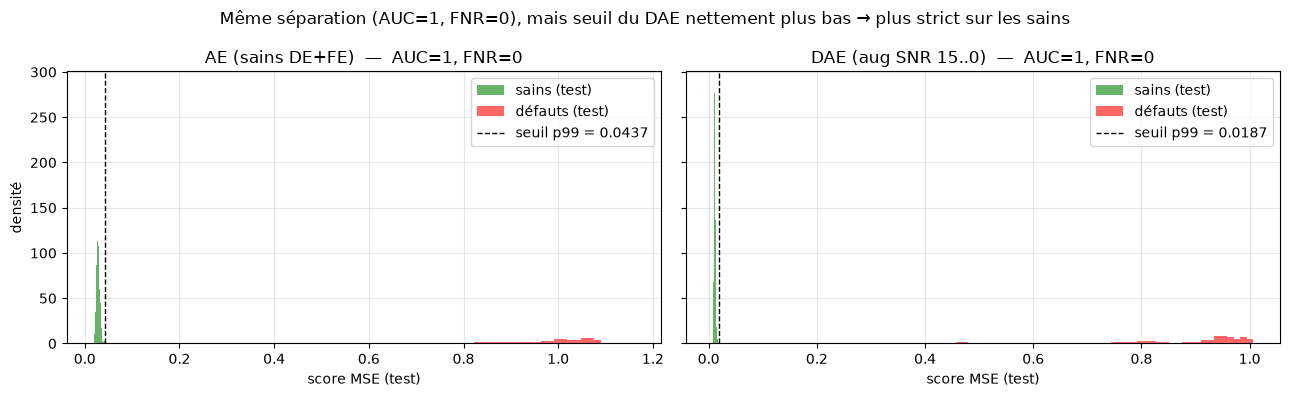

In [7]:
# === Illustration : seuil DAE plus bas, séparation identique ===
y_test = (infos["defaut_sain"].to_numpy()[i_test] == "Défaut")
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)

for ax, modele, tag in [(axes[0], modele_AE, "AE (sains DE+FE)"),
                        (axes[1], modele_DAE, "DAE (aug SNR 15..0)")]:
    score = score_mse(modele, SBNorm)
    seuil = np.percentile(score[i_train][sain[i_train]], 99)      # p99 du train sain
    s = score[i_test]
    ax.hist(s[~y_test], bins=60, density=True, alpha=0.6, color="green", label="sains (test)")
    ax.hist(s[y_test],  bins=60, density=True, alpha=0.6, color="red",   label="défauts (test)")
    ax.axvline(seuil, color="black", ls="--", lw=1, label=f"seuil p99 = {seuil:.4f}")
    ax.set_title(f"{tag}  —  AUC=1, FNR=0"); ax.set_xlabel("score MSE (test)")
    ax.legend(); ax.grid(alpha=0.3)
axes[0].set_ylabel("densité")
fig.suptitle("Même séparation (AUC=1, FNR=0), mais seuil du DAE nettement plus bas → plus strict sur les sains")
plt.tight_layout(); plt.show()

In [15]:
# Max fit avant d'enregistrer le modèle
modele_DAE = models.conv1d_ae(SBNorm.shape[1])
modele_DAE.fit(X_aug[..., None], Y_aug[..., None], epochs=100, batch_size=64,
               validation_split=0.1, verbose=1,
               callbacks=[EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)])
df_DAE = evaluer_par_capteur(modele_DAE, "DAE (aug SNR 15..0)")
display(df_DAE)

display(pd.concat([df_AE, df_DAE]).set_index(["config", "capteur"]))

Epoch 1/100
291/291 ━━━━━━━━━━━━━━━━━━━━ 34s 103ms/step - loss: 0.1541 - val_loss: 0.2513
Epoch 2/100
291/291 ━━━━━━━━━━━━━━━━━━━━ 31s 107ms/step - loss: 0.0679 - val_loss: 0.2356
Epoch 3/100
291/291 ━━━━━━━━━━━━━━━━━━━━ 31s 106ms/step - loss: 0.0635 - val_loss: 0.2237
Epoch 4/100
291/291 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - loss: 0.0607 - val_loss: 0.2173
Epoch 5/100
291/291 ━━━━━━━━━━━━━━━━━━━━ 30s 105ms/step - loss: 0.0596 - val_loss: 0.2152
Epoch 6/100
291/291 ━━━━━━━━━━━━━━━━━━━━ 30s 104ms/step - loss: 0.0586 - val_loss: 0.2126
Epoch 7/100
291/291 ━━━━━━━━━━━━━━━━━━━━ 30s 105ms/step - loss: 0.0581 - val_loss: 0.2107
Epoch 8/100
291/291 ━━━━━━━━━━━━━━━━━━━━ 30s 104ms/step - loss: 0.0575 - val_loss: 0.2104
Epoch 9/100
291/291 ━━━━━━━━━━━━━━━━━━━━ 30s 105ms/step - loss: 0.0572 - val_loss: 0.2088
Epoch 10/100
291/291 ━━━━━━━━━━━━━━━━━━━━ 31s 105ms/step - loss: 0.0569 - val_loss: 0.2092
Epoch 11/100
291/291 ━━━━━━━━━━━━━━━━━━━━ 30s 102ms/step - loss: 0.0564 - val_loss: 0.2066
Epoch 12

,config,capteur,seuil_p99,AUC,FPR,FNR
0,DAE (aug SNR 15..0),DE,0.0083,1.0,0.0000,0.0
1,DAE (aug SNR 15..0),FE,0.0083,1.0,0.0042,0.0


seuil_p99  AUC     FPR  FNR
config              capteur                             
AE (sains DE+FE)    DE          0.0437  1.0  0.0037  0.0
                    FE          0.0437  1.0  0.0014  0.0
DAE (aug SNR 15..0) DE          0.0083  1.0  0.0000  0.0
                    FE          0.0083  1.0  0.0042  0.0

In [17]:
modele_DAE.save(RACINE / "Sources" / "Fitted_models" / "DAE_fitted.keras")

In [18]:
from tensorflow import keras

Fitted_Model = keras.models.load_model(RACINE / "Sources" / "Fitted_models" / "DAE_fitted.keras")

In [19]:
df_DAE = evaluer_par_capteur(Fitted_Model, "DAE (aug SNR 15..0)")
display(df_DAE)

display(pd.concat([df_AE, df_DAE]).set_index(["config", "capteur"]))

,config,capteur,seuil_p99,AUC,FPR,FNR
0,DAE (aug SNR 15..0),DE,0.0083,1.0,0.0000,0.0
1,DAE (aug SNR 15..0),FE,0.0083,1.0,0.0042,0.0


seuil_p99  AUC     FPR  FNR
config              capteur                             
AE (sains DE+FE)    DE          0.0437  1.0  0.0037  0.0
                    FE          0.0437  1.0  0.0014  0.0
DAE (aug SNR 15..0) DE          0.0083  1.0  0.0000  0.0
                    FE          0.0083  1.0  0.0042  0.0